# Experiment 02: Training rows

**Question:** does lgbm_building get better with more training rows?

Card: [exp02_training_rows.md](../experiments/exp02_training_rows.md).

- **Model:** lgbm_building from [exp01_building.ipynb](exp01_building.ipynb): LightGBM on the 33 shared features plus
  `building_id` as a categorical, untuned (500 trees, learning rate 0.1, 63 leaves).
- **Training rows:** 0.5M, 1M, 2M (used so far), 4M, 8M and 14M, sampled from the ~14.5M clean rows outside each
  validation block.
- **Validation rows:** the same 500K per fold for every size, so only the training rows change.

Same 4 seasonal folds as every notebook, anomalies dropped from training only ([data.split](../../ashrae/data.py)).
Every run is logged to MLflow, experiment `ashrae-baseline-training-rows`.

In [1]:
import sys
from time import perf_counter, strftime

import lightgbm as lgb
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

sys.path.insert(0, "../..")  # the ashrae package lives in the homework folder
from ashrae.config import FOLDS, METERS, MLFLOW_URI
from ashrae.data import read_processed, split
from ashrae.features import build_features
from ashrae.metrics import rmsle, rmsle_by_meter
from ashrae.tracking import log_run

EXPERIMENT = "ashrae-baseline-training-rows"
SESSION = strftime("%Y-%m-%d %H:%M:%S")  # tag shared by this execution's runs
N_TRAINS = [500_000, 1_000_000, 2_000_000, 4_000_000, 8_000_000, 14_000_000]
N_VAL = 500_000  # validation rows per fold, the same for every training size
LGBM_PARAMS = {"n_estimators": 500, "learning_rate": 0.1, "num_leaves": 63}

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Training

Per fold and size: lgbm_building, scored on the fold's fixed validation rows. Logged per run: validation RMSLE on all
rows, on clean rows and per meter, training RMSLE, and training time.

In [2]:
df = read_processed()
BUILDING = pd.CategoricalDtype(range(int(df.building_id.max()) + 1))  # all ids, so every fold shares categories


def with_building(X, rows):
    """`X` plus `building_id` as a categorical, which LightGBM splits on directly."""
    return X.assign(building_id=rows.building_id.astype(int).astype(BUILDING).to_numpy())


for fold, months in FOLDS.items():
    for n_train in N_TRAINS:
        train_df, val_df = split(df, months, n_train, N_VAL)  # validation rows don't depend on n_train
        year_median = train_df.year_built.median()
        X_train = with_building(build_features(train_df, year_median), train_df)
        X_val = with_building(build_features(val_df, year_median), val_df)
        y_train = np.log1p(train_df.meter_reading.to_numpy(dtype="float32"))
        y_val = np.log1p(val_df.meter_reading.to_numpy(dtype="float32"))
        clean = ~val_df.anomaly.to_numpy()
        start = perf_counter()
        model = lgb.LGBMRegressor(**LGBM_PARAMS, random_state=0, verbose=-1).fit(X_train, y_train)
        train_seconds = perf_counter() - start
        pred = np.clip(model.predict(X_val), 0, None)
        metrics = {**rmsle_by_meter(y_val, pred, val_df.meter.to_numpy()),
                   "val_rmsle_clean": rmsle(y_val[clean], pred[clean]),
                   "train_rmsle": rmsle(y_train, model.predict(X_train)),
                   "train_seconds": train_seconds}
        log_run(EXPERIMENT, f"lgbm_building | {n_train:,} rows | {fold}",
                params={**LGBM_PARAMS, "n_train": n_train, "n_val": N_VAL, "n_features": X_train.shape[1]},
                metrics=metrics,
                tags={"session": SESSION, "fold": fold, "model": "lgbm_building", "notebook": "exp02_training_rows"})
        print(f"{fold} {n_train:>10,} rows: val RMSLE {metrics['val_rmsle']:.3f} "
              f"(clean rows {metrics['val_rmsle_clean']:.3f}), {train_seconds:.0f} s")

2026/10/11 11:29:03 INFO mlflow.tracking.fluent: Experiment with name 'ashrae-baseline-training-rows' does not exist. Creating a new experiment.


Jan–Mar    500,000 rows: val RMSLE 1.434 (clean rows 0.958), 8 s


Jan–Mar  1,000,000 rows: val RMSLE 1.435 (clean rows 0.955), 8 s


Jan–Mar  2,000,000 rows: val RMSLE 1.434 (clean rows 0.951), 10 s


Jan–Mar  4,000,000 rows: val RMSLE 1.436 (clean rows 0.953), 13 s


...

Oct–Dec  1,000,000 rows: val RMSLE 1.118 (clean rows 1.026), 8 s


Oct–Dec  2,000,000 rows: val RMSLE 1.116 (clean rows 1.024), 10 s


Oct–Dec  4,000,000 rows: val RMSLE 1.111 (clean rows 1.018), 13 s


Oct–Dec  8,000,000 rows: val RMSLE 1.111 (clean rows 1.018), 25 s


Oct–Dec 14,000,000 rows: val RMSLE 1.111 (clean rows 1.019), 36 s


## Results

Read from MLflow, the latest session of this notebook, so this section runs without retraining. The figure is saved to
[figures/](../figures/exp02_training_rows.png) and logged as an artifact of each run.

In [2]:
mlflow.set_tracking_uri(MLFLOW_URI)
runs = mlflow.search_runs(experiment_names=[EXPERIMENT], filter_string="tags.notebook = 'exp02_training_rows'")
runs = runs[runs["tags.session"] == runs["tags.session"].max()]
results = runs.rename(columns=lambda c: c.removeprefix("metrics.").removeprefix("tags.").removeprefix("params."))
results["n_train"] = results.n_train.astype(int)
print(f"MLflow session {results.session.iloc[0]}: {len(results)} runs")

table = results.pivot(index="n_train", columns="fold", values="val_rmsle").loc[N_TRAINS, list(FOLDS)]
averages = results.groupby("n_train")[["val_rmsle", "val_rmsle_clean", "train_rmsle", "train_seconds"]].mean()
table["average"] = averages.val_rmsle
table["average, clean rows"] = averages.val_rmsle_clean
table["training"] = averages.train_rmsle
table["seconds per fit"] = averages.train_seconds
display(table.round(3).rename_axis("RMSLE, all rows unless noted"))

meters = results.groupby("n_train")[[f"val_rmsle_{name}" for name in METERS.values()]].mean().loc[N_TRAINS]
display(meters.rename(columns=lambda c: c.removeprefix("val_rmsle_")).round(3).rename_axis("fold average, all rows"))

MLflow session 2026-10-11 11:28:52: 24 runs


fold,Jan–Mar,Apr–Jun,Jul–Sep,Oct–Dec,average,"average, clean rows",training,seconds per fit
"RMSLE, all rows unless noted",,,,,,,,
500000,1.434,1.241,1.097,1.118,1.223,0.967,0.801,7.739
1000000,1.435,1.236,1.088,1.118,1.219,0.962,0.811,8.593
2000000,1.434,1.231,1.087,1.116,1.217,0.959,0.815,10.048
4000000,1.436,1.233,1.083,1.111,1.216,0.957,0.818,13.484
8000000,1.433,1.231,1.085,1.111,1.215,0.957,0.820,23.644
14000000,1.429,1.228,1.082,1.111,1.213,0.954,0.819,34.642


,electricity,chilledwater,steam,hotwater
"fold average, all rows",,,,
500000,0.975,1.409,1.566,1.592
1000000,0.976,1.399,1.561,1.586
2000000,0.975,1.392,1.560,1.583
4000000,0.974,1.394,1.557,1.575
8000000,0.974,1.391,1.558,1.577
14000000,0.974,1.384,1.552,1.579


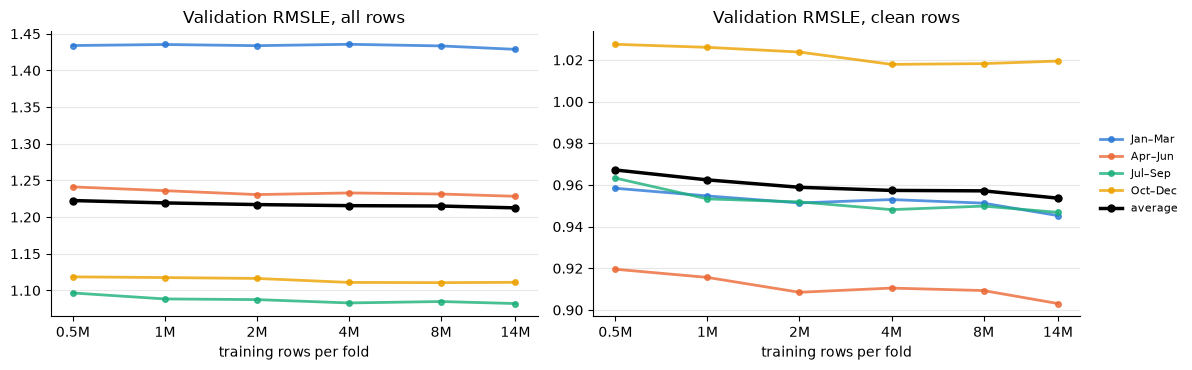

In [3]:
COLORS = dict(zip(FOLDS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, key, rows in zip(axes, ["val_rmsle", "val_rmsle_clean"], ["all rows", "clean rows"]):
    scores = results.pivot(index="n_train", columns="fold", values=key).loc[N_TRAINS, list(FOLDS)]
    for fold in FOLDS:
        ax.plot(N_TRAINS, scores[fold], color=COLORS[fold], lw=2, marker="o", ms=4, alpha=0.8, label=fold)
    ax.plot(N_TRAINS, scores.mean(axis=1), color="black", lw=2.5, marker="o", ms=5, label="average")
    ax.set_xscale("log")
    ax.set(xticks=N_TRAINS, xticklabels=[f"{n / 1e6:g}M" for n in N_TRAINS], xlabel="training rows per fold",
           title=f"Validation RMSLE, {rows}")
    ax.minorticks_off()
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
axes[1].legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5))
fig.savefig("../figures/exp02_training_rows.png", dpi=150, bbox_inches="tight")

# The figure covers the whole experiment, so every run of this session gets a copy
client = mlflow.MlflowClient()
for run_id in runs.run_id:
    client.log_artifact(run_id, "../figures/exp02_training_rows.png")

## Findings

Fold averages on all rows unless noted. The 2M row matches [exp01_building.ipynb](exp01_building.ipynb) (1.217, clean rows
0.959), and 4M matches [ensemble.ipynb](../../ensemble/notebooks/ensemble.ipynb) (1.216).

- **More rows barely help:** 0.5M → 14M gives 1.223 → 1.213 (−0.010), clean rows 0.967 → 0.954 (−0.013), about the
  ~0.01 noise level. From 2M to 14M it's −0.004 (clean rows −0.005).
- **Every fold is flat:** no fold changes by more than 0.013 over the whole range.
- **Chilled water gains most:** 1.409 → 1.384; electricity doesn't change (0.975 → 0.974).
- **Training RMSLE rises** 0.801 → 0.819: with more rows the trees memorize less, but validation hardly moves.
- **Cost:** 10 s per fit at 2M, 35 s at 14M.

Data size isn't what limits lgbm_building.